# 🧪 Notebook 06 — Unitary Coupled-Cluster Operators

> **Module:** Quantum Computing for Computational Chemistry\
> **Level:** Intermediate\
> **Estimated time:** 90 min\
> **Prerequisites:** Fermionic operators, Jordan–Wigner mapping, Hadamard test, and Pauli exponentials

---

## 📌 Overview

This notebook constructs unitary coupled-cluster generators, prepares correlated states, and studies first-order Trotterization as a circuit approximation to exact unitary evolution.

## 🎯 Learning objectives

By the end of this notebook, you should be able to:

- Construct and verify an anti-Hermitian cluster generator.
- Build exact and Trotterized state preparation.
- Measure overlaps and energies.

## 🔑 Key concepts

`UCC` · `anti-Hermiticity` · `unitary evolution` · `Trotter error` · `overlap` · `Hadamard test` · `Pauli-string circuit`

## 🧩 Structure

1. Cluster generator
2. Reference determinant
3. Exact and Trotter evolution
4. Overlap and energy analysis
5. Circuit implementation

## 📚 Resources

- OpenFermion, SciPy, and Qiskit documentation
- Previous notebook: `exponential.ipynb`

### ⏱️ Expected outcome

You will understand and implement a UCC state in a quantum circuit using Trotter approximation.

# Unitary coupled-cluster operators

Coupled-cluster methods generate correlated states by applying excitation operators to a reference determinant. In the unitary form used here, the generator is anti-Hermitian, so its exponential is unitary and preserves the norm of the state.

$$|\psi\rangle=e^{\hat T} |\psi_0\rangle$$


In [2]:
from openfermion import FermionOperator, QubitOperator, jordan_wigner, lambda_norm, hermitian_conjugated
from openfermion import hermitian_conjugated, normal_ordered, get_sparse_operator
import matplotlib.pyplot as plt
from sympy.printing.pretty.pretty_symbology import line_width

### Generator

The operator

$$T=a_1a_2^\dagger-a_2a_1^\dagger$$

has the form $T=A-A^\dagger$ and is therefore anti-Hermitian: $T^\dagger=-T$. Consequently, $e^{aT}$ is unitary for real $a$. The following cells verify this property algebraically and map the generator to qubit Pauli operators.

In [3]:
T = FermionOperator('1 2^') - FermionOperator('2 1^') # must be antiHermitian

In [4]:
def is_antihermitian(op):
    hermitian_part = normal_ordered(op + hermitian_conjugated(op))
    return len(hermitian_part.terms) == 0

print('T is antihermitian?', is_antihermitian(T))

T is antihermitian? True


### Reference

The reference is the determinant

$|\psi_0\rangle=a_0^\dagger a_1^\dagger|\mathrm{vac}\rangle$.

In [5]:
# a b a b a b
state = FermionOperator('0^ 1^')

## State preparation

Here we apply the Coupled Cluster operator to the reference state. To observe the effect a scaling parameter $a$ applied to the generator. For this exemple compares the exact evolution compared with the Trotterization approach.

The exact routine applies $e^{aT}$ as one matrix exponential.
The Trotter routine factors the mapped generator into Pauli terms and applies their exponentials sequentially,

$$e^{a\sum_j P_j}\approx\prod_j e^{aP_j}. $$

The overlaps with two reference determinants show population transfer caused by the excitation generator. Since the generator is anti-Hermitian, the exact evolution should preserve $\langle\psi|\psi\rangle=1$.

In [6]:
# convert T into qubit operators
t_qubit = jordan_wigner(T)
print(t_qubit)


0.5j [X1 Y2] +
-0.5j [Y1 X2]


In [7]:
# apply CC operator to reference state
from scipy.sparse.linalg import expm, expm_multiply

state_sparse = get_sparse_operator(state, n_qubits=3)
for op in t_qubit.get_operators():
    sparse_op = get_sparse_operator(op)
    state_sparse = expm_multiply(sparse_op, state_sparse)

# vector form
vec_state = state_sparse[:, 0].toarray()
print(vec_state)

# check normalization
print('\nnormalization', (vec_state.T.conj() @ vec_state)[0, 0].real)

[[ 0.        +0.j]
 [ 0.        +0.j]
 [ 0.        +0.j]
 [ 0.        +0.j]
 [ 0.        +0.j]
 [-0.84147098+0.j]
 [ 0.54030231+0.j]
 [ 0.        +0.j]]

normalization 1.0


In [8]:
# overlap with respect to reference state
state_sparse_ini = get_sparse_operator(state, n_qubits=3)
print(f'<psi_0|psi>: ', (state_sparse_ini.T.conj() @ state_sparse)[0, 0].real)

<psi_0|psi>:  0.5403023058681397


### Exact evolution

$|\psi(a)\rangle = e^{a\sum_j P_j} |\psi_0\rangle $


In [9]:
from scipy.sparse.linalg import expm, expm_multiply

def build_ucc_operator(a):
    state_sparse = get_sparse_operator(state, n_qubits=3)
    sparse_op = get_sparse_operator(a * t_qubit)
    state_sparse = expm_multiply(sparse_op, state_sparse)
    return state_sparse

### Trotterized approach (1 trotter step)

$|\psi(a)\rangle = \prod_j e^{aP_j} |\psi_0\rangle $

In [10]:
def build_ucc_operator_trotter(a):
    state_sparse = get_sparse_operator(state, n_qubits=3)
    for op in (a*t_qubit).get_operators():
        sparse_op = get_sparse_operator(op)
        state_sparse = expm_multiply(sparse_op, state_sparse)
    return state_sparse

### Reference states to use as basis to analyze evolved state

This example uses to basis state to analyze $|\psi (a)\rangle$

$|\phi_1\rangle=a_0^\dagger a_1^\dagger|\mathrm{vac}\rangle$

$|\phi_2\rangle=a_0^\dagger a_2^\dagger|\mathrm{vac}\rangle$


In [11]:
state_ref1 = FermionOperator('0^ 1^')
state_ref2 = FermionOperator('0^ 2^')

sparse_basis1 = get_sparse_operator(state_ref1, n_qubits=3)
sparse_basis2 = get_sparse_operator(state_ref2, n_qubits=3)

<>:19: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\p'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:23: SyntaxWarning: invalid escape sequence '\p'
<>:19: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\p'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:23: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_506346/2042272704.py:19: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(exact_1, label='$<\phi_1 | \psi(t)>$ exact', linewidth= 3)
/tmp/ipykernel_506346/2042272704.py:20: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(exact_2, label='$<\phi_2 | \psi(t)>$ exact', linewidth= 3)
/tmp/ipykernel_506346/2042272704.py:22: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(trotter_1, '--', label='$<\phi_1 | \psi(a)>$ trotter', linewidth= 3)
/tmp/ipykernel_506346/2042272704.py:23: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(trotter_2, '--', label='$

(-1.0, 1.0)

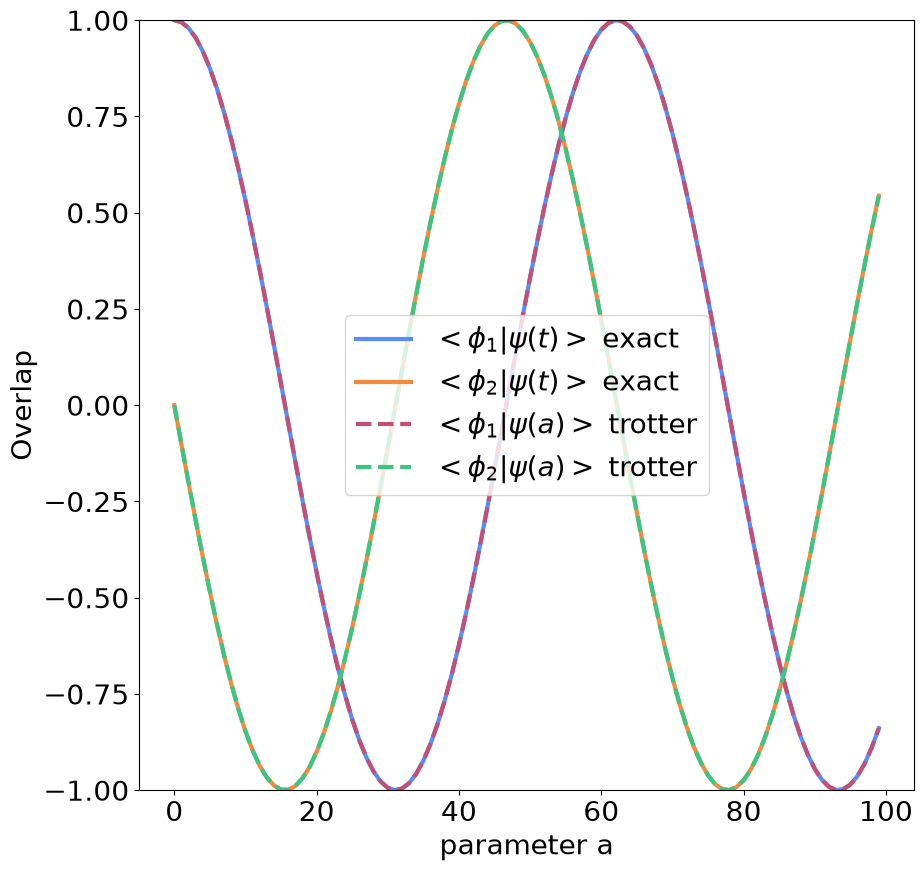

In [27]:
exact_1 = []
exact_2 = []
trotter_1 = []
trotter_2 = []
import numpy as np
for a in np.linspace(0, 10, 100):

    sparse_state = build_ucc_operator(a)

    exact_1.append((sparse_basis1.T.conj() @ sparse_state)[0, 0].real)
    exact_2.append((sparse_basis2.T.conj() @ sparse_state)[0, 0].real)

    sparse_state = build_ucc_operator_trotter(a)

    trotter_1.append((sparse_basis1.T.conj() @ sparse_state)[0, 0].real)
    trotter_2.append((sparse_basis2.T.conj() @ sparse_state)[0, 0].real)

plt.figure(figsize=(10, 10))
plt.plot(exact_1, label='$<\phi_1 | \psi(t)>$ exact', linewidth= 3)
plt.plot(exact_2, label='$<\phi_2 | \psi(t)>$ exact', linewidth= 3)

plt.plot(trotter_1, '--', label='$<\phi_1 | \psi(a)>$ trotter', linewidth= 3)
plt.plot(trotter_2, '--', label='$<\phi_2 | \psi(a)>$ trotter', linewidth= 3)

plt.legend(fontsize=20)
plt.xlabel("parameter a", fontsize=20)
plt.ylabel("Overlap", fontsize=20)
plt.tick_params(axis="both", labelsize=20)
plt.ylim(-1, 1)

## Energy along the unitary path

The Hamiltonian in the next section is used as an observable for the states $|\psi(a)\rangle=e^{aT}|\psi_0\rangle$. The plotted quantity is

$$E(a)=\langle\psi(a)|H|\psi(a)\rangle. $$

Here $a$ is a variational cluster parameter, not physical time. It changes the trial state and can therefore change the measured energy.

Define a simple made up hermitian Hamiltonian

$H = \frac{1}{2} a_1^\dagger a_1$

Since T and H do not commute we expect $\langle\psi(a)|H|\psi(a)\rangle$ to NOT be conserved.

In [13]:
Hh = 0.5 * FermionOperator('1^ 1')
ha_qubit = jordan_wigner(Hh)
Hh_sparse = get_sparse_operator(ha_qubit, n_qubits=3)


commutator = T * Hh - Hh * T
print('Commute?', len(commutator.terms) == 0)

Commute? False


<>:13: SyntaxWarning: invalid escape sequence '\p'
<>:14: SyntaxWarning: invalid escape sequence '\p'
<>:13: SyntaxWarning: invalid escape sequence '\p'
<>:14: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_506346/3259363357.py:13: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(exact, label='$<\psi_1 | H | \psi(t)>$ exact', linewidth= 3)
/tmp/ipykernel_506346/3259363357.py:14: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(trotter, '--', label='$<\psi_1 | H | \psi(t)>$ trotter', linewidth= 3)


(0.0, 1.0)

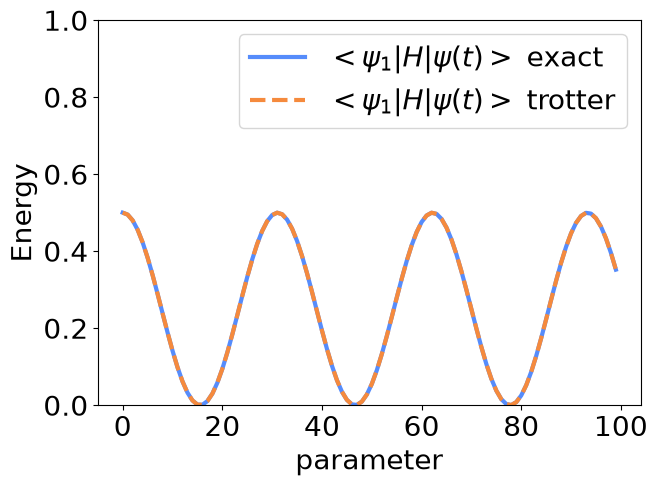

In [35]:
exact = []
trotter = []
import numpy as np
for p in np.linspace(0, 10, 100):

    sparse_state = build_ucc_operator(p)
    exact.append((sparse_state.T.conj() @ Hh_sparse @ sparse_state)[0, 0].real)

    sparse_state = build_ucc_operator_trotter(p)
    trotter.append((sparse_state.T.conj() @ Hh_sparse @  sparse_state)[0, 0].real)

plt.figure(figsize=(7, 5))
plt.plot(exact, label='$<\psi_1 | H | \psi(t)>$ exact', linewidth= 3)
plt.plot(trotter, '--', label='$<\psi_1 | H | \psi(t)>$ trotter', linewidth= 3)
plt.legend(fontsize=20)
plt.tick_params(axis="both", labelsize=20)
plt.xlabel('parameter',fontsize=20)
plt.ylabel('Energy',fontsize=20)
plt.ylim(0, 1)

## Pauli-string circuit implementation

The Qiskit circuit prepares the reference occupation with X gates and compiles each Pauli term of the Jordan-Wigner generator. Basis changes convert X and Y factors to Z, a CNOT ladder accumulates parity, and an RZ gate applies the corresponding phase. Because $R_z(\phi)=e^{-i\phi Z/2}$, the circuit angle contains a factor of two.

The final sampling routine measures the Hamiltonian term by term and estimates the energy from Pauli parities.

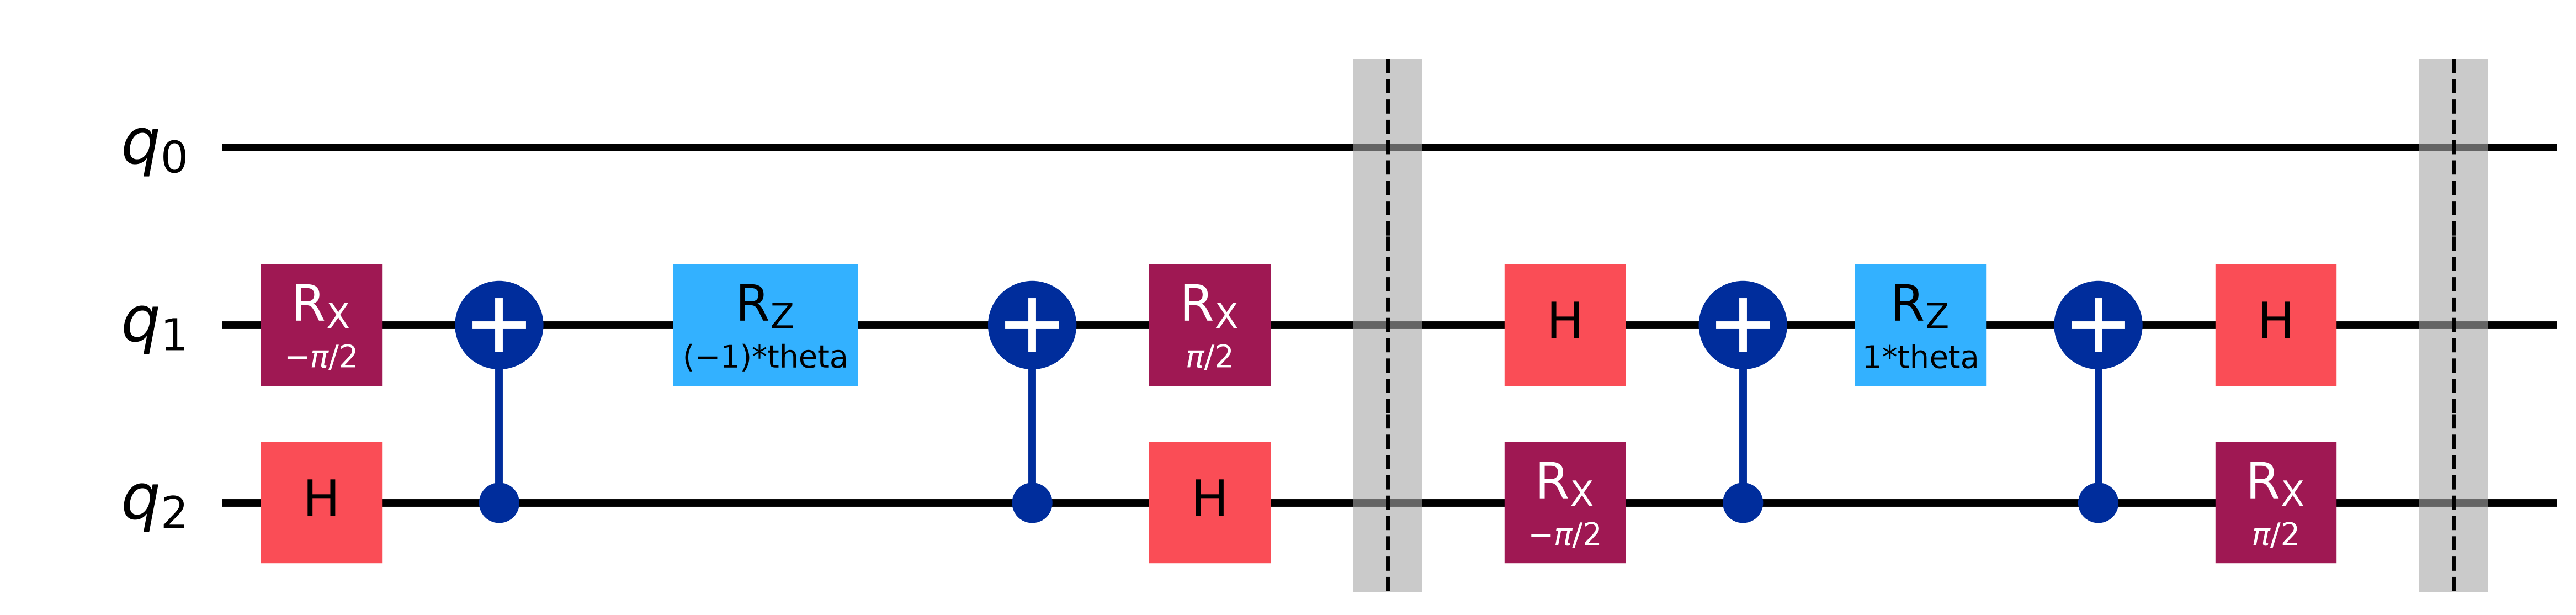

In [41]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc = QuantumCircuit(3)

# reference state
#qc.x(0)
#qc.x(1)

i_op = 0
for op, coef in t_qubit.terms.items():

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(-np.pi / 2, [qubit])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    if len(op) > 0:
        qc.rz(2*theta * coef.imag, op[0][0])

    for qubit, pauli in reversed(op[1:]):
        qc.cx(qubit, op[0][0])

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    qc.barrier()

qc.draw(output="mpl", scale=5.0)

In [16]:
from qiskit.primitives import StatevectorSampler

def cost_function(params):
    energy = 0.0
    for op, coeff in ha_qubit.terms.items():

        # setup circuit
        qc_prep = QuantumCircuit(3)

        # reference
        qc_prep.x(0)
        qc_prep.x(1)

        qc_bound = qc_prep.compose(qc.assign_parameters(params))

        # qc_bound = qc.assign_parameters(params)
        qc_meas = qc_bound.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        # add mesure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        shots = sum(counts.values())

        # compute expected value
        for bitstring, count in counts.items():

            parity = 1
            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

<>:8: SyntaxWarning: invalid escape sequence '\p'
<>:8: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_506346/1873836588.py:8: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(trotter, label='$<\psi_1 | H | \psi(t)>$ trotter', linewidth= 3)


(0.0, 1.0)

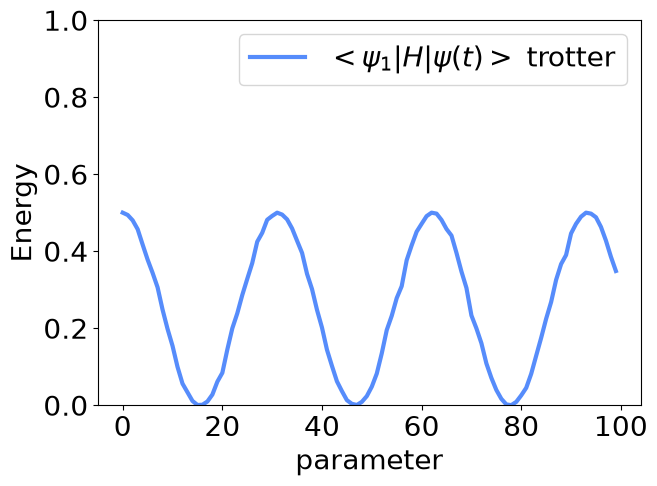

In [45]:
trotter = []
import numpy as np
for t in np.linspace(0, 10, 100):
    energy = cost_function([t])
    trotter.append(energy)

plt.figure(figsize=(7, 5))
plt.plot(trotter, label='$<\psi_1 | H | \psi(t)>$ trotter', linewidth= 3)
plt.legend()
plt.xlabel('parameter')
plt.ylabel('energy')
plt.legend(fontsize=20)
plt.tick_params(axis="both", labelsize=20)
plt.xlabel('parameter',fontsize=20)
plt.ylabel('Energy',fontsize=20)

plt.ylim(0, 1)

## Overlap

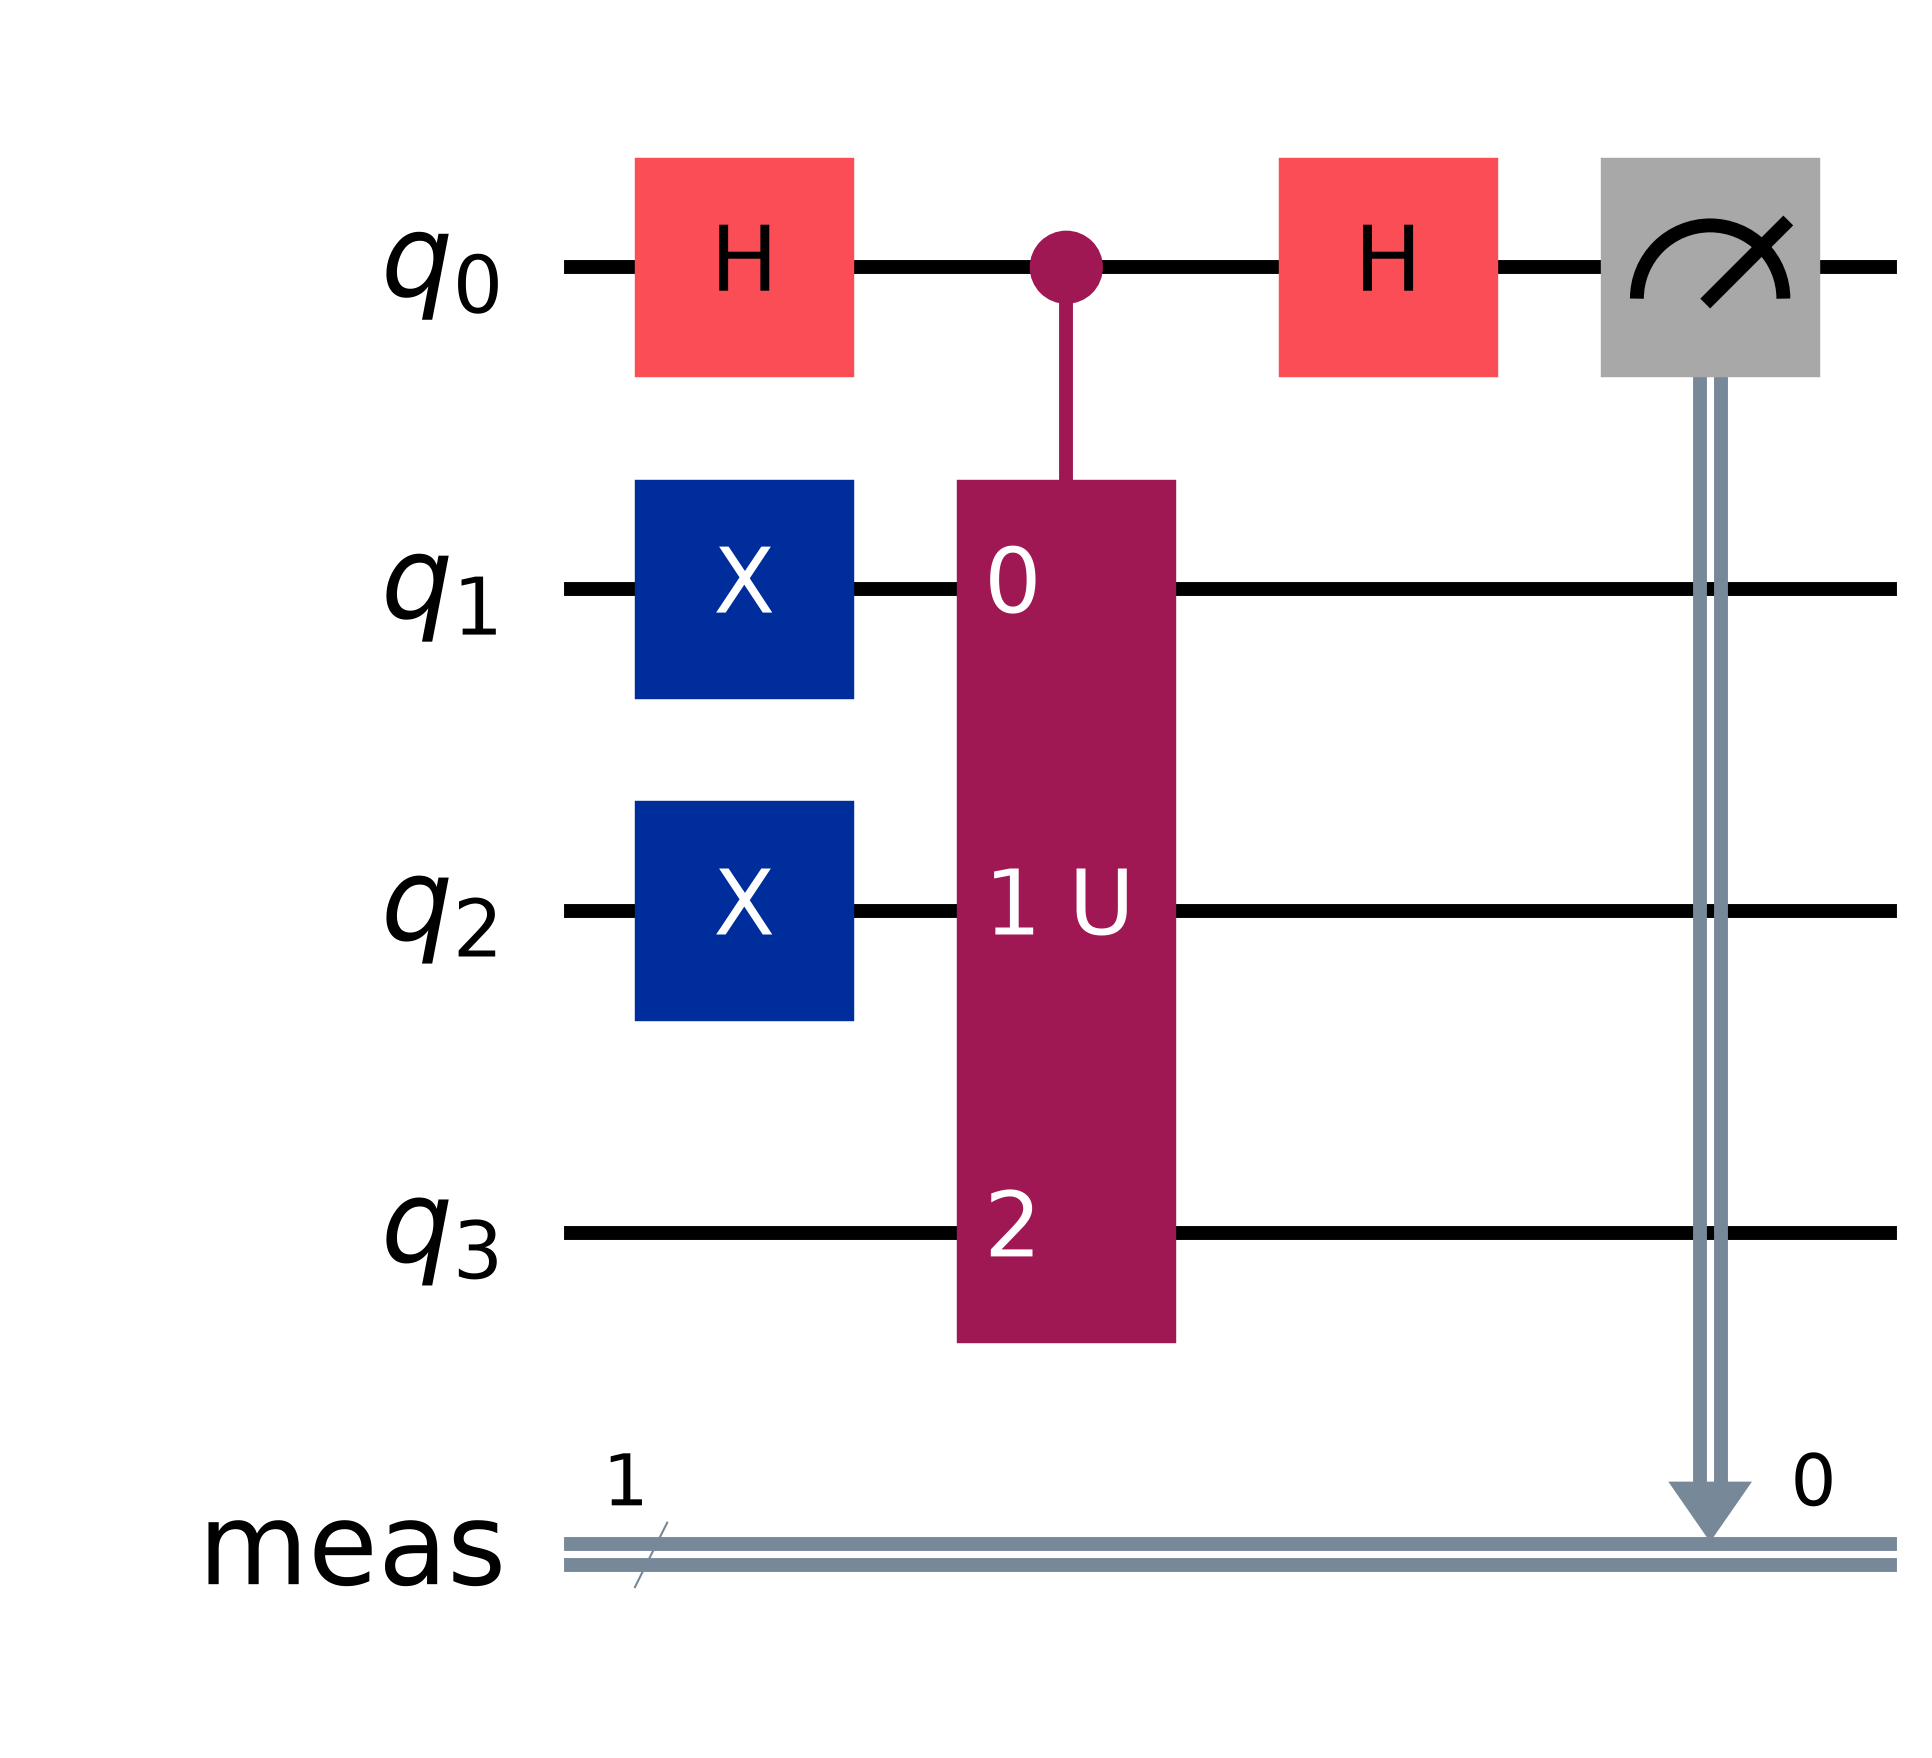

In [42]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
c_reg = ClassicalRegister(1, "meas")
q = QuantumRegister(4, r'q')

def remove_barriers(qc):
    qc = qc.copy()
    qc.data = [
        instruction
        for instruction in qc.data
        if instruction.operation.name != "barrier"
    ]
    return qc

def evolution_gate(params):

    # state evolution
    evol = remove_barriers(qc).copy()
    evol = evol.assign_parameters(params)

    # Conditional transformation |101> -> |110>
    #evol.x(1)
    #evol.x(2)

    return evol.to_gate(label="U")


# Build the ansatz
def get_hadamard_test_circuit(params, imaginary_part=False):

    qc_test = QuantumCircuit(q, c_reg)

    # reference
    qc_test.x(1)
    qc_test.x(2)

    qc_test.h(0)


    if imaginary_part:
        qc_test.s(0) # for imaginary part

    U_gate = evolution_gate(params)

    U_controlled_gate = U_gate.control(1)

    qc_test.append(U_controlled_gate, [0, 1, 2, 3])
    qc_test.h(0)

    qc_test.measure(q[0], c_reg)

    return qc_test

get_hadamard_test_circuit([0.1]).draw('mpl', scale=5.0)

<>:21: SyntaxWarning: invalid escape sequence '\p'
<>:21: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_506346/3362594774.py:21: SyntaxWarning: invalid escape sequence '\p'
  plt.plot(overlaps, label='$<\psi_2 | \psi(t)>$')


1.0
0.864672
0.496718
-0.00919
-0.509174
-0.872498
-0.999874
-0.855258
-0.482494
0.024812
0.523402
0.879984
0.999488
0.84735
0.467256
-0.040414
-0.536958
-0.887338
-0.99878
-0.839952


(-1.0, 1.0)

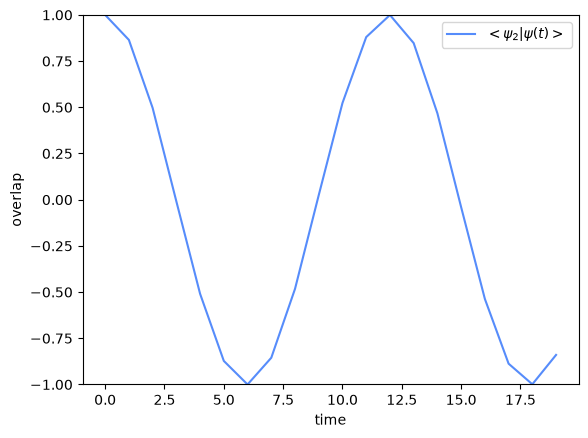

In [19]:
def cost_function_overlap(params):

    sampler = StatevectorSampler()

    n_shots = 1000000

    # real part
    qc_test = get_hadamard_test_circuit(params, imaginary_part=False)
    result = sampler.run([qc_test], shots=n_shots).result()
    counts = result[0].data.meas.get_counts()
    overlap_real = (counts.get('0', 0) - counts.get('1', 0)) / n_shots

    print(overlap_real)
    return overlap_real

overlaps = []
import numpy as np
for t in np.linspace(0, 10, 20):
    overlaps.append(cost_function_overlap([t]))

plt.plot(overlaps, label='$<\psi_2 | \psi(t)>$')
plt.legend()
plt.xlabel('time')
plt.ylabel('overlap')
plt.ylim(-1, 1)